[Open in Colab](https://colab.research.google.com/github/nz-gravity/sgvb_psd/blob/main/docs/examples/ET_example.ipynb)

# ET example
Read a bounded slice of the existing 16 MB ET sample. Downsample with an
anti-aliasing filter from 2048 to 256 Hz, then fit the 10–100 Hz band with
independent vmapped Cholesky rows. This is a short demonstration, not the
full ET paper analysis. Downloads are cached; the figures are saved in this notebook.

## Setup

In [1]:
# Colab installs the package; local runs use the project environment.
import subprocess
import sys

try:
    import google.colab
except ImportError:
    print("Using the local SGVB environment. See the repository's uv setup instructions.")
else:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "jax[cpu]==0.6.2", "numpyro==0.19.0",
        "sgvb_psd[examples] @ git+https://github.com/nz-gravity/sgvb_psd.git@main",
    ])


Using the local SGVB environment. See the repository's uv setup instructions.


In [2]:
import warnings
# Progress widgets are unused; ipywidgets is optional in the local environment.
warnings.filterwarnings("ignore", message="IProgress not found.*")

from pathlib import Path
from time import perf_counter
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sgvb_psd.psd_estimator import PSDEstimator
import jax

%matplotlib inline

plt.rcParams.update({"font.family": "sans-serif", "font.size": 11,
                     "axes.labelsize": 11, "axes.titlesize": 12,
                     "legend.fontsize": 8, "figure.dpi": 110,
                     "text.usetex": False})
print("JAX", jax.__version__, "devices:", jax.devices())
# Deliberately small demonstration budgets, not a convergence certificate.
BUDGET = dict(N_theta=8, nchunks=2, ntrain_map=1000,
              n_elbo_maximisation_steps=300, N_samples=96, seed=7)


20:10:27|SGVB-PSD|INFO| No GPU detected. Running on CPU.
JAX 0.6.2 devices: [CpuDevice(id=0)]


## Data and reference

In [3]:
import h5py
from urllib.request import urlopen
DATA_PATH = Path("et_data.h5")
if not DATA_PATH.exists():
    url = "https://raw.githubusercontent.com/nz-gravity/sgvb_psd/main/docs/examples/et_data.h5"
    temporary = DATA_PATH.with_suffix(".part")
    with urlopen(url, timeout=60) as response, temporary.open("wb") as destination:
        import shutil
        shutil.copyfileobj(response, destination)
    temporary.replace(DATA_PATH)
with h5py.File(DATA_PATH, "r") as handle:
    raw = np.column_stack([handle[k][:32768] for k in ("X", "Y", "Z")])
fs = 256.
data = signal.resample_poly(raw, up=1, down=8, axis=0)
data -= data.mean(axis=0)
assert data.shape == (4096, 3) and np.all(np.isfinite(data))
print("ET sample after anti-aliased downsampling:", data.shape, fs)


ET sample after anti-aliased downsampling: (4096, 3) 256.0


## Fit the spectrum

In [4]:
start = perf_counter()
estimator = PSDEstimator(data, fs=fs, reference_psd=None,
                         parallel_rows=True, fmin_for_analysis=10., fmax_for_analysis=100., **BUDGET)
_ = estimator.run(lr=.003)  # Explicit rate: no costly hyperparameter search.
runtime = perf_counter() - start
assert np.all(np.isfinite(estimator.pointwise_ci))
assert np.all(np.isfinite(estimator.inference_runner.kdl_losses))
print(f"{len(data)} samples × {data.shape[1]} channels; fit {runtime:.2f} s")
if estimator.parallel_rows:
    print("Independent vmapped Cholesky-row dimensions:", estimator.inference_runner.row_dimensions)


20:10:27|SGVB-PSD|INFO| Dividing data (4096, 3) into (2, 2048, 3) chunks
20:10:27|SGVB-PSD|INFO| Reducing the number of frequencies to be analyzed from 1024 to 100.0...
20:10:27|SGVB-PSD|INFO| Final PSD will be of shape: 720 x 3 x 3
20:10:27|SGVB-PSD|WARNING| Input data not standardised!
20:10:27|SGVB-PSD|INFO| Using provided learning rate: 0.003
20:10:27|SGVB-PSD|INFO| Training model
20:10:30|SGVB-PSD|INFO| Model trained in 2.30s
20:10:30|SGVB-PSD|INFO| Computing posterior PSDs
4096 samples × 3 channels; fit 4.55 s
Independent vmapped Cholesky-row dimensions: (19, 60, 101)


## Plot the results

The saved figures show the fitted spectra and pointwise 90% variational intervals.

In [5]:
def show_fit(estimator, data, labels, truth=None, reference=None):
    """Two-sided densities and magnitude-squared coherence, no hidden rescaling."""
    from matplotlib.ticker import NullFormatter
    p = data.shape[1]
    fig, axes = plt.subplots(p, 1, figsize=(7.2, 2.8*p), squeeze=False)
    for i, ax in enumerate(axes[:, 0]):
        fw, pw = signal.welch(data[:, i], fs=estimator.fs, window="boxcar",
                              nperseg=estimator.nt_per_chunk, noverlap=0,
                              detrend=False, return_onesided=False)
        keep = (fw >= estimator.freq[0]) & (fw <= estimator.freq[-1])
        ax.loglog(fw[keep], pw[keep], color="0.65", lw=.7, label="Blocked periodogram")
        q = estimator.pointwise_ci[:, :, i, i].real
        ax.fill_between(estimator.freq, q[0], q[2], alpha=.25)
        ax.loglog(estimator.freq, q[1], label="SGVB median")
        if truth is not None:
            ax.loglog(estimator.freq, truth(estimator.freq)[:, i, i].real, "k--", lw=1, label="Known simulation truth")
        if reference is not None:
            ax.loglog(estimator.freq, reference(estimator.freq)[:, i, i].real, ":", color="C2", lw=1, label="Fixed reference")
        ax.set(title=labels[i], xlabel="Frequency [Hz]", ylabel="Two-sided PSD [input units²/Hz]")
        ticks = np.geomspace(estimator.freq[0], estimator.freq[-1], 4)
        ax.set_xticks(ticks, labels=[f"{f:.2g}" for f in ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.tick_params(axis="both", labelsize=10)
        ax.grid(which="major", alpha=.2)
        ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()
    if p > 1:
        fig, ax = plt.subplots(figsize=(7.2, 3.4))
        s = estimator.psd_all
        for i in range(p):
            for j in range(i):
                coh = abs(s[:, :, i, j])**2/(s[:, :, i, i].real*s[:, :, j, j].real)
                q = np.quantile(coh, [.05, .5, .95], axis=0)
                line, = ax.plot(estimator.freq, q[1], label=f"{labels[i]}–{labels[j]}")
                ax.fill_between(estimator.freq, q[0], q[2], alpha=.15, color=line.get_color())
                if truth is not None:
                    known = truth(estimator.freq)
                    known_coh = abs(known[:, i, j])**2/(known[:, i, i].real*known[:, j, j].real)
                    ax.plot(estimator.freq, known_coh, "--", color=line.get_color(), label=f"{labels[i]}–{labels[j]} truth")
        ax.set(xlabel="Frequency [Hz]", ylabel="Magnitude-squared coherence", ylim=(0, 1))
        ax.grid(alpha=.2); ax.legend(fontsize=9); fig.tight_layout(); plt.show()


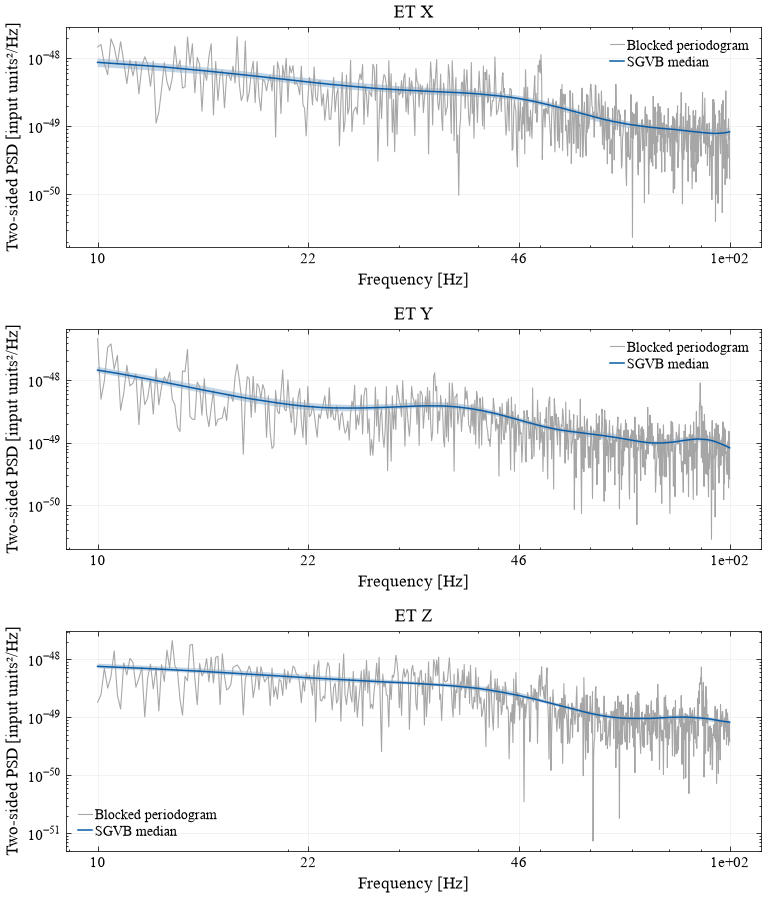

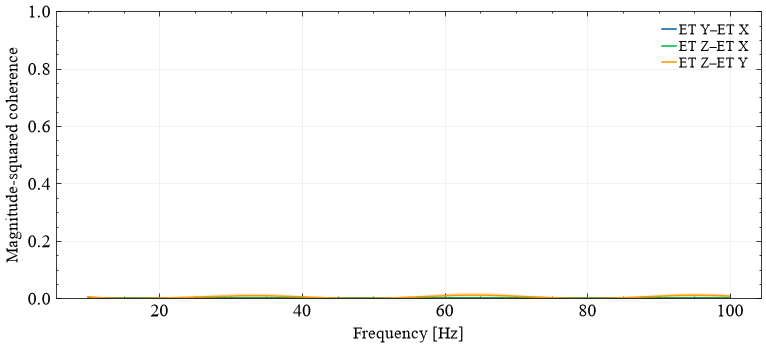

In [6]:
show_fit(estimator, data, ["ET X", "ET Y", "ET Z"])


## Interpretation and budget

The shaded bands are pointwise 90% variational intervals. Cheap settings
show the workflow; they do not establish convergence or calibrated coverage.
Increase the data duration, basis size and optimization budgets only for an
explicit analysis/validation plan. Compilation is included in the first-fit
time. JAX batches rows with `vmap`; actual CPU/GPU scheduling is device dependent.
Each row still includes regression on preceding channels, so cross-spectra
are retained. This is modified-Cholesky SGVB, not the removed eigenbasis mode or the
collapsed conditional-theta method in LogPSplinePSD.
